# Predicción de recompra a 60 días
**Adianet Hurtado Quispe**

Caso The Look, Machine Learning Engineer. Este notebook reproduce la preparación, evaluación temporal y predicción a partir de una extracción SQL real de BigQuery. El objetivo es una nueva orden creada en (primera compra, primera compra + 60 días]. Los ítems de una orden no cuentan como compras distintas. Los datos son de un ecommerce ficticio.

**Ejecución:** abrir desde la raíz del repositorio y ejecutar todas las celdas. La copia local comprimida permite reproducir resultados sin credenciales. Para otro corte, regenerar primero la base SQL. La arquitectura AWS es un diseño, no un despliegue.

**Resultado principal:** 79.634 clientes, 70.741 maduros y tasa global de 7,20%. El candidato seleccionado por validación no aporta un ranking útil en test (AP 0,1563 frente a referencia 0,1593, lift top20 1,003). Se recomienda mantenerlo fuera de producción y mejorar la señal antes de un piloto comercial. Los resultados se muestran a continuación.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from pipeline import run_pipeline, prepare_data, temporal_split, FEATURES
DATA_PATH = ROOT / 'model_base.csv.gz'
CUTOFF = '2025-02-14'
OUTPUT = ROOT / 'reports/run'
plt.rcParams.update({'figure.figsize': (10,4.8), 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':11})


## 1 SQL y decisiones de datos
La extracción usa `orders` como hecho de órdenes y obtiene la primera por `ROW_NUMBER(created_at, order_id)`. Cada CTE vuelve a una fila por cliente antes del cruce final. Los controles verifican unicidad de claves y correspondencias.

Se incluyen todos los estados en el objetivo de **orden creada**. Filtrar la primera compra por su estado final permitiría que información posterior cambie el instante de scoring. `Cancelled` se excluye solamente en una etiqueta alternativa de sensibilidad sobre futuras órdenes. `Returned` se mantiene porque hubo una orden creada. Antes de producción, negocio debe acordar si quiere orden creada, pagada o ingreso neto.

El último día del snapshot, 14/02/2025, está incompleto. El corte exclusivo es 14/02/2025 00:00 UTC. Los clientes sin ventana completa de 60 días conservan target nulo. Las variables de navegación se limitan a los 30 días anteriores, incluyendo t0. Los ítems se usan únicamente si `item.created_at <= first_order_at`. El catálogo se considera estático para categoría, supuesto que debe sustituirse por una dimensión histórica si cambia. Los timestamps representan tiempo del evento y se asume disponibilidad al mismo instante: en producción se necesita también tiempo de ingesta. No se usan estados finales, fecha de envío o devolución, próxima compra ni IDs como features.

### 00_schema_and_states.sql
```sql
SELECT table_name,column_name,data_type
FROM `bussiness-case-tyc.bussiness_case_ecommerce.INFORMATION_SCHEMA.COLUMNS`
WHERE table_name IN ('orders','order_items','users','products','events')
ORDER BY table_name,ordinal_position;

SELECT status, COUNT(*) AS filas, COUNT(DISTINCT order_id) AS ordenes_unicas,
COUNT(DISTINCT user_id) AS clientes, MIN(created_at) AS primera_fecha,
MAX(created_at) AS ultima_fecha, COUNTIF(order_id IS NULL) AS ids_orden_nulos,
COUNTIF(user_id IS NULL) AS ids_cliente_nulos, COUNTIF(created_at IS NULL) AS fechas_nulas
FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
GROUP BY status ORDER BY filas DESC;

```

### 01_quality.sql
```sql
-- Solo lectura. Corte exclusivo: primer día posterior al último día completo.
WITH o AS (SELECT * FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`),
i AS (SELECT * FROM `bussiness-case-tyc.bussiness_case_ecommerce.order_items`),
u AS (SELECT * FROM `bussiness-case-tyc.bussiness_case_ecommerce.users`),
p AS (SELECT * FROM `bussiness-case-tyc.bussiness_case_ecommerce.products`)
SELECT 'orders_rows' AS control, COUNT(*) AS valor FROM o
UNION ALL SELECT 'orders_duplicate_ids', COUNT(*)-COUNT(DISTINCT order_id) FROM o
UNION ALL SELECT 'orders_null_keys_dates', COUNTIF(order_id IS NULL OR user_id IS NULL OR created_at IS NULL) FROM o
UNION ALL SELECT 'users_duplicate_ids', COUNT(*)-COUNT(DISTINCT id) FROM u
UNION ALL SELECT 'products_duplicate_ids', COUNT(*)-COUNT(DISTINCT id) FROM p
UNION ALL SELECT 'items_duplicate_ids', COUNT(*)-COUNT(DISTINCT id) FROM i
UNION ALL SELECT 'orders_without_user', COUNT(*) FROM o LEFT JOIN u ON o.user_id=u.id WHERE u.id IS NULL
UNION ALL SELECT 'items_without_order', COUNT(*) FROM i LEFT JOIN o USING(order_id) WHERE o.order_id IS NULL
UNION ALL SELECT 'items_without_product', COUNT(*) FROM i LEFT JOIN p ON i.product_id=p.id WHERE p.id IS NULL
UNION ALL SELECT 'items_user_mismatch', COUNT(*) FROM i JOIN o USING(order_id) WHERE i.user_id!=o.user_id
UNION ALL SELECT 'items_after_order_timestamp', COUNT(*) FROM i JOIN o USING(order_id) WHERE i.created_at>o.created_at
UNION ALL SELECT 'items_null_price', COUNTIF(sale_price IS NULL) FROM i
UNION ALL SELECT 'items_negative_price', COUNTIF(sale_price<0) FROM i
UNION ALL SELECT 'orders_without_items', COUNT(*) FROM o LEFT JOIN (SELECT DISTINCT order_id FROM i) z USING(order_id) WHERE z.order_id IS NULL
UNION ALL SELECT 'orders_before_user_registration', COUNT(*) FROM o JOIN u ON o.user_id=u.id WHERE o.created_at<u.created_at;

```

### 02_model_base.sql
```sql
-- BigQuery Standard SQL. Una fila por cliente. No modifica el origen.
-- Target principal: nueva ORDEN CREADA, independientemente de su estado posterior.
-- Los estados finales no están disponibles históricamente y no filtran features.
-- Corte exclusivo 2025-02-14 UTC: se omite el último día parcial del snapshot.
DECLARE cutoff_ts TIMESTAMP DEFAULT TIMESTAMP('2025-02-14 00:00:00+00');

WITH orders_asof AS (
  SELECT order_id,user_id,created_at,status,num_of_item
  FROM `bussiness-case-tyc.bussiness_case_ecommerce.orders`
  WHERE created_at < cutoff_ts AND user_id IS NOT NULL AND order_id IS NOT NULL
), first_order AS (
  SELECT * FROM orders_asof
  QUALIFY ROW_NUMBER() OVER(PARTITION BY user_id ORDER BY created_at,order_id)=1
), labels AS (
  SELECT f.user_id,
    MIN(IF(o.created_at>f.created_at,o.created_at,NULL)) AS next_order_at,
    COUNTIF(o.created_at>f.created_at AND o.created_at<=TIMESTAMP_ADD(f.created_at, INTERVAL 60 DAY))>0 AS repeat_60,
    COUNTIF(o.created_at>f.created_at AND o.created_at<=TIMESTAMP_ADD(f.created_at, INTERVAL 60 DAY) AND o.status!='Cancelled')>0 AS repeat_60_non_cancelled
  FROM first_order f LEFT JOIN orders_asof o USING(user_id)
  GROUP BY f.user_id
), basket AS (
  -- Agregar antes de unir evita multiplicar clientes por ítems.
  SELECT f.user_id, COUNT(i.id) AS observed_items,
    SUM(i.sale_price) AS basket_value,
    COUNT(DISTINCT i.product_id) AS unique_products,
    COUNT(DISTINCT p.category) AS unique_categories,
    ARRAY_AGG(p.category IGNORE NULLS ORDER BY i.sale_price DESC,i.id LIMIT 1)[SAFE_OFFSET(0)] AS main_category
  FROM first_order f
  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.order_items` i
    ON f.order_id=i.order_id AND f.user_id=i.user_id AND i.created_at<=f.created_at
  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.products` p ON i.product_id=p.id
  GROUP BY f.user_id
), activity AS (
  SELECT f.user_id, COUNT(e.id) AS events_30d,
    COUNT(DISTINCT e.session_id) AS sessions_30d,
    COUNTIF(e.event_type='product') AS product_views_30d,
    ARRAY_AGG(e.traffic_source IGNORE NULLS ORDER BY e.created_at DESC,e.id DESC LIMIT 1)[SAFE_OFFSET(0)] AS last_traffic_source,
    ARRAY_AGG(e.browser IGNORE NULLS ORDER BY e.created_at DESC,e.id DESC LIMIT 1)[SAFE_OFFSET(0)] AS last_browser
  FROM first_order f
  LEFT JOIN `bussiness-case-tyc.bussiness_case_ecommerce.events` e
    ON f.user_id=e.user_id AND e.created_at<=f.created_at
    AND e.created_at>=TIMESTAMP_SUB(f.created_at, INTERVAL 30 DAY)
    AND e.created_at<cutoff_ts
  GROUP BY f.user_id
)
SELECT f.user_id, f.order_id AS first_order_id, f.created_at AS first_order_at,
  cutoff_ts AS cutoff_ts,
  TIMESTAMP_ADD(f.created_at,INTERVAL 60 DAY)<cutoff_ts AS is_mature,
  IF(TIMESTAMP_ADD(f.created_at,INTERVAL 60 DAY)<cutoff_ts,CAST(l.repeat_60 AS INT64),NULL) AS target,
  IF(TIMESTAMP_ADD(f.created_at,INTERVAL 60 DAY)<cutoff_ts,CAST(l.repeat_60_non_cancelled AS INT64),NULL) AS target_non_cancelled,
  TIMESTAMP_DIFF(l.next_order_at,f.created_at,SECOND)/86400.0 AS days_to_next_order,
  f.num_of_item AS declared_items,
  b.observed_items,b.basket_value,b.unique_products,b.unique_categories,b.main_category,
  a.events_30d,a.sessions_30d,a.product_views_30d,a.last_traffic_source,a.last_browser,
  EXTRACT(DAYOFWEEK FROM f.created_at) AS purchase_dayofweek,
  EXTRACT(HOUR FROM f.created_at) AS purchase_hour,
  EXTRACT(MONTH FROM f.created_at) AS purchase_month
FROM first_order f
LEFT JOIN labels l USING(user_id)
LEFT JOIN basket b USING(user_id)
LEFT JOIN activity a USING(user_id);

```

In [2]:
quality = json.loads((ROOT/'source_quality.json').read_text(encoding='utf-8'))
display(pd.Series(quality['controls'],name='Valor').to_frame())
display(pd.Series(quality['states'],name='Órdenes por estado').to_frame())


,Valor
orders_rows,124596
orders_duplicate_ids,0
orders_null_keys_dates,0
users_duplicate_ids,0
products_duplicate_ids,0
items_duplicate_ids,0
orders_without_user,0
items_without_order,0
items_without_product,0
items_user_mismatch,0


,Órdenes por estado
Shipped,37212
Complete,31157
Processing,24957
Cancelled,18714
Returned,12556


## 2 Preparación automatizada y entrenamiento
`run_pipeline` valida la base, separa períodos, ajusta transformaciones solo en entrenamiento, compara modelos, selecciona por AP de validación y escribe predicciones sin append. No requiere pasos manuales entre preparación y predicción. Parámetros de corte y períodos configurables. Un cambio de corte requiere una nueva extracción SQL para mantener la coherencia point-in-time.

Las funciones importadas se muestran a continuación para que el notebook sea auditable. El mismo código funciona como script CLI.

In [3]:
import inspect
import pipeline
print(inspect.getsource(pipeline))

"""Preparación, evaluación temporal y scoring reproducibles del caso The Look."""
from pathlib import Path
import argparse
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import joblib
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
    precision_score, recall_score, f1_score, brier_score_loss, confusion_matrix)

NUM = ['declared_items','observed_items','basket_value','unique_products',
       'unique_categories','events_30d','sessions_30d','product_views_30d']
CAT = ['main_category','last_traffic_source','last_browser',
       'purchase_dayofweek','purchase_hour','purcha

In [4]:
df, train, val, test, models, predictions, summary, scored = run_pipeline(
    DATA_PATH, OUTPUT, cutoff=CUTOFF,
    validation_start='2024-01-01',validation_end='2024-07-01',test_start='2024-09-01')
display(pd.Series({k:summary[k] for k in ['n_clients','n_mature','n_censored',
    'overall_rate','non_cancelled_rate','basket_missing_rate','events_zero_rate']}))
display(pd.DataFrame(summary['splits']).T)
assert len(df)==quality['base_rows_expected'], 'Extracción incompleta'


n_clients              79634.000000
n_mature               70741.000000
n_censored              8893.000000
overall_rate               0.072009
non_cancelled_rate         0.061435
basket_missing_rate        0.202426
events_zero_rate           0.000000
dtype: float64

,n,start,end,rate
train,41576,2019-01-22 14:50:00+00:00,2023-11-01 18:31:00+00:00,0.04416
validation,11677,2024-01-01 00:04:00+00:00,2024-06-30 18:49:00+00:00,0.085981
test,9390,2024-09-01 00:45:00+00:00,2024-12-15 18:57:00+00:00,0.159318


## 3 Análisis que orienta decisiones
Las tasas descriptivas se calculan solo sobre clientes con seguimiento completo. Los segmentos muestran asociación, no efecto causal. El tiempo entre compras se presenta para quienes recompraron en la ventana de 60 días y no representa a todos los clientes.

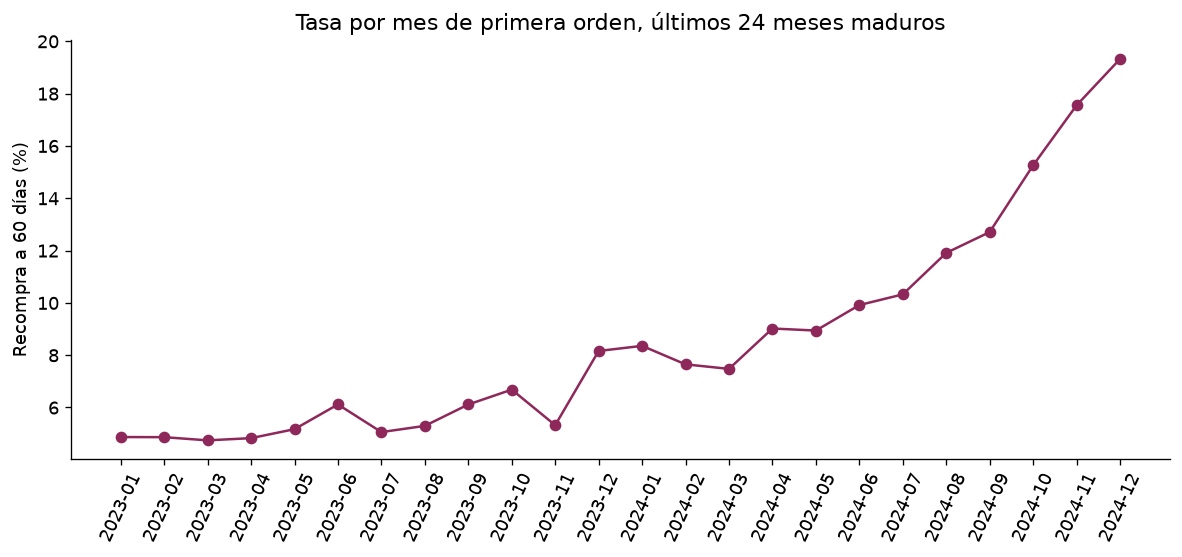

In [5]:
mature=df[df.target.notna()].copy()
mature['cohort']=mature.first_order_at.dt.strftime('%Y-%m')
cohorts=mature.groupby('cohort').agg(n=('target','size'),rate=('target','mean')).reset_index()
cohorts.to_csv(OUTPUT/'cohorts.csv',index=False)
fig,ax=plt.subplots()
recent=cohorts.tail(24)
ax.plot(recent.cohort,recent.rate*100,color='#8E285B',marker='o')
ax.set(ylabel='Recompra a 60 días (%)',title='Tasa por mes de primera orden, últimos 24 meses maduros')
ax.tick_params(axis='x',rotation=65)
fig.tight_layout(); fig.savefig(OUTPUT/'01_cohorts.png',dpi=160); plt.show()


Mediana de días entre recompradores: 29.0


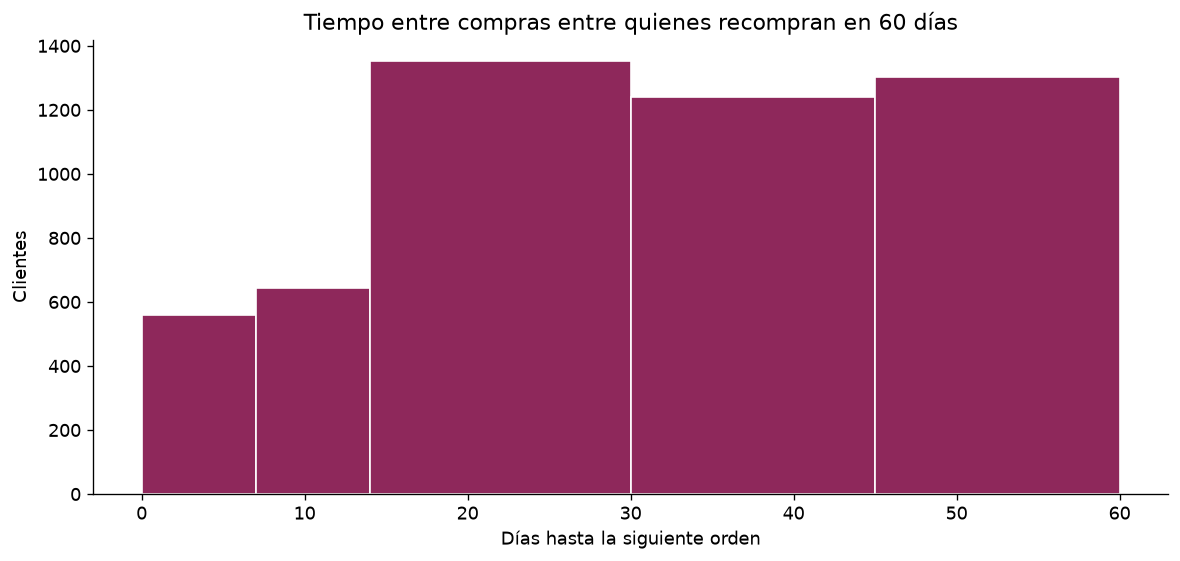

In [6]:
repeat=mature.loc[mature.target.eq(1),'days_to_next_order'].dropna()
bins=[0,7,14,30,45,60]
hist,_=np.histogram(repeat,bins=bins)
pd.DataFrame({'interval':['0-7','7-14','14-30','30-45','45-60'],'n':hist}).to_csv(OUTPUT/'repeat_days.csv',index=False)
fig,ax=plt.subplots()
ax.hist(repeat,bins=bins,color='#8E285B',edgecolor='white')
ax.set(xlabel='Días hasta la siguiente orden',ylabel='Clientes',title='Tiempo entre compras entre quienes recompran en 60 días')
fig.tight_layout();fig.savefig(OUTPUT/'02_repeat_days.png',dpi=160);plt.show()
print('Mediana de días entre recompradores:',round(repeat.median(),1))


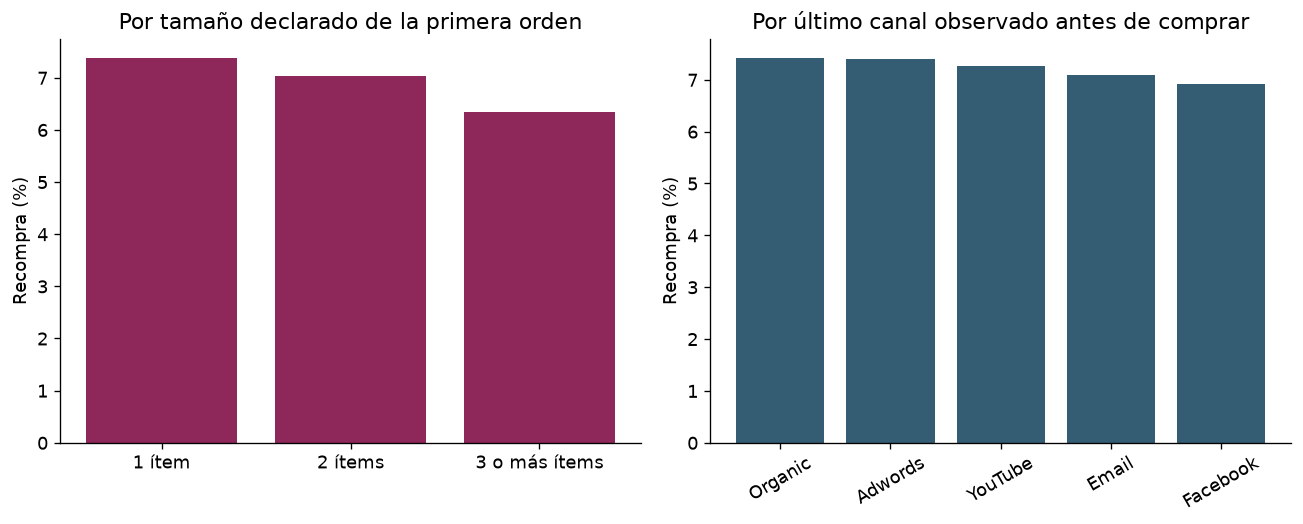

,segment,n,rate
0,1 ítem,49491,0.073731
1,2 ítems,14220,0.070253
2,3 o más ítems,7030,0.063442


,n,rate
last_traffic_source,,
Organic,3534,0.074137
Adwords,21138,0.074085
YouTube,7025,0.072598
Email,31861,0.070902
Facebook,7183,0.069191


In [7]:
mature['segment']=pd.cut(mature.declared_items,bins=[0,1,2,np.inf],labels=['1 ítem','2 ítems','3 o más ítems'])
segments=mature.groupby('segment',observed=True).agg(n=('target','size'),rate=('target','mean')).reset_index()
segments.to_csv(OUTPUT/'segments.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
axes[0].bar(segments.segment.astype(str),segments.rate*100,color='#8E285B')
axes[0].set(ylabel='Recompra (%)',title='Por tamaño declarado de la primera orden')
channels=mature.groupby('last_traffic_source').agg(n=('target','size'),rate=('target','mean')).query('n>=500').sort_values('rate',ascending=False)
channels.to_csv(OUTPUT/'channels.csv')
axes[1].bar(channels.index,channels.rate*100,color='#345C73')
axes[1].set(ylabel='Recompra (%)',title='Por último canal observado antes de comprar')
axes[1].tick_params(axis='x',rotation=30)
fig.tight_layout();fig.savefig(OUTPUT/'03_segments.png',dpi=160);plt.show()
display(segments);display(channels)


## 4 Evaluación temporal
Entrenamiento: primeras compras cuyos 60 días concluyen antes de 01/01/2024. Validación: primeras compras de enero a junio de 2024, con etiquetas maduras antes de 01/09/2024. Test: primeras compras desde 01/09/2024 y con seguimiento completo al corte. Las compras de los períodos de embargo se conservan para análisis, pero no se usan en la evaluación.

Referencia: probabilidad constante igual a la prevalencia de entrenamiento. Regresión logística: modelo interpretable. HistGradientBoosting: interacciones no lineales con complejidad limitada. No se realiza búsqueda exhaustiva. AP (Average Precision) resume la curva precision-recall y se reporta expresamente como AP, sin confundirla con área trapezoidal. La referencia AP equivale a la prevalencia del conjunto evaluado. Selección por AP de validación, umbral por F1 de validación. El top 20% es una capacidad comercial hipotética, fijada antes de mirar el test. Se reportan precision, recall, F1, Brier y lift sobre test. El umbral F1 no representa un óptimo económico.

In [8]:
display(pd.DataFrame(summary['validation']).T.drop(columns=['confusion_matrix']))
display(pd.DataFrame(summary['test']).T.drop(columns=['confusion_matrix']))
print('Modelo seleccionado exclusivamente por validación:',summary['selected'])
print('Sensibilidad al excluir futuras órdenes canceladas:',summary['sensitivity_test_non_cancelled'])
print('AP validación sin navegación:',summary['ablation_no_events_validation_ap'])


Modelo seleccionado exclusivamente por validación: boosting
Sensibilidad al excluir futuras órdenes canceladas: {'n': 9390, 'prevalence': 0.1402555910543131, 'ap': 0.13946895336981333, 'precision': 0.14016402172755352, 'recall': 0.9992406985573272, 'f1': 0.24584345226975526, 'brier': 0.12971937272376174, 'threshold': 0.031023921763200967, 'precision_top20': 0.14643237486687966, 'recall_top20': 0.2088078967350038, 'lift_top20': 1.044039483675019, 'confusion_matrix': [[0, 8073], [1, 1316]]}
AP validación sin navegación: 0.08663183120799639


,n,prevalence,ap,precision,recall,f1,brier,threshold,precision_top20,recall_top20,lift_top20
baseline,11677,0.085981,0.085981,0.085981,1.0,0.158347,0.080337,0.04416,0.085981,0.200051,1.0
logistic,11677,0.085981,0.082202,0.086102,0.999004,0.158539,0.080538,0.02466,0.078767,0.183267,0.916099
boosting,11677,0.085981,0.086186,0.086018,1.0,0.15841,0.080401,0.031024,0.085188,0.198207,0.990781


,n,prevalence,ap,precision,recall,f1,brier,threshold,precision_top20,recall_top20,lift_top20
baseline,9390,0.159318,0.159318,0.159318,1.0,0.274848,0.147198,0.04416,0.159318,0.2,1.0
logistic,9390,0.159318,0.162832,0.159193,0.996658,0.274535,0.146939,0.02466,0.159744,0.200535,1.002674
boosting,9390,0.159318,0.156251,0.159229,0.999332,0.27469,0.147092,0.031024,0.159744,0.200535,1.002674


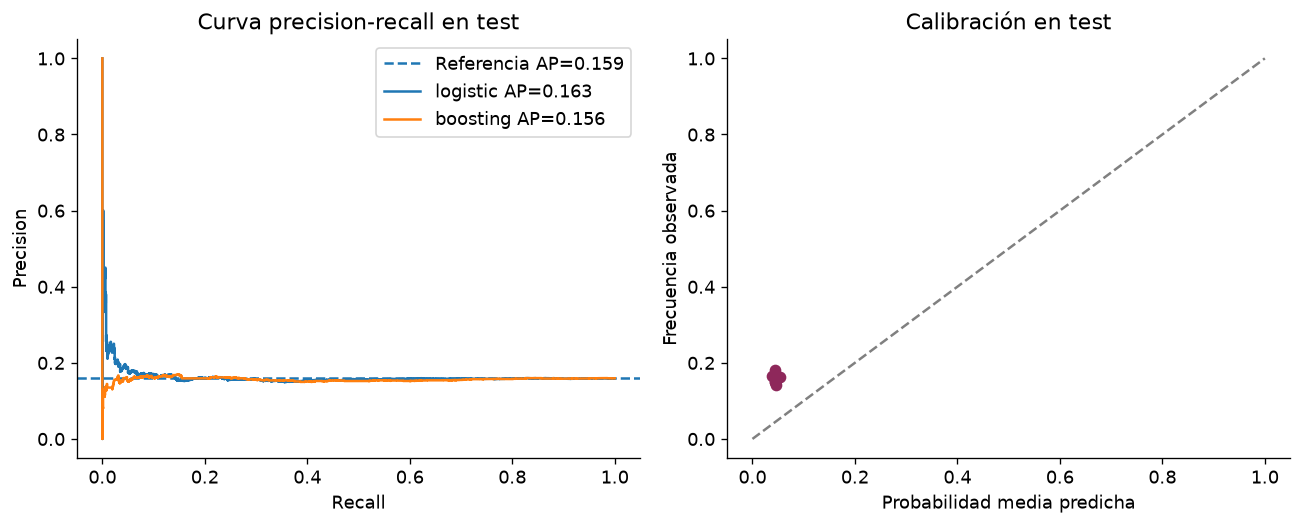

In [9]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
pr_export=[]
for kind,p in predictions.items():
    precision,recall,_=precision_recall_curve(test.target,p)
    if kind == 'baseline':
        axes[0].axhline(test.target.mean(), linestyle='--', label=f"Referencia AP={summary['test'][kind]['ap']:.3f}")
    else:
        axes[0].step(recall,precision,where='post',label=f"{kind} AP={summary['test'][kind]['ap']:.3f}")
    ix=np.linspace(0,len(recall)-1,min(80,len(recall)),dtype=int)
    pr_export.extend({'model':kind,'recall':float(recall[i]),'precision':float(precision[i])} for i in ix)
axes[0].set(xlabel='Recall',ylabel='Precision',title='Curva precision-recall en test');axes[0].legend()
chosen=summary['selected'];p=predictions[chosen]
frac,mean=calibration_curve(test.target,p,n_bins=8,strategy='quantile')
axes[1].plot(mean,frac,'o-',color='#8E285B');axes[1].plot([0,1],[0,1],'--',color='gray')
axes[1].set(xlabel='Probabilidad media predicha',ylabel='Frecuencia observada',title='Calibración en test')
pd.DataFrame(pr_export).to_csv(OUTPUT/'pr_curve.csv',index=False)
fig.tight_layout();fig.savefig(OUTPUT/'04_evaluation.png',dpi=160);plt.show()


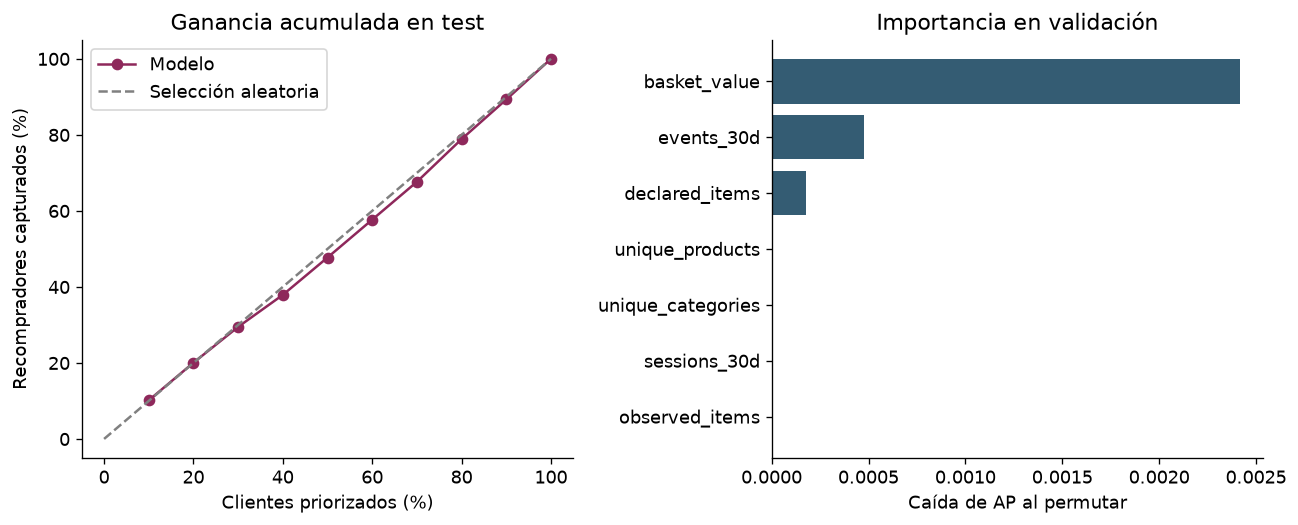

,user_id,first_order_at,cutoff_ts,probability_repurchase_60d,prediction,model_version
71232,106,2024-12-21 03:51:00+00:00,2025-02-14 00:00:00+00:00,0.057741,1,boosting_v1_cutoff_2025-02-14
75307,8927,2025-01-25 16:09:00+00:00,2025-02-14 00:00:00+00:00,0.056820,1,boosting_v1_cutoff_2025-02-14
72073,64909,2024-12-28 18:19:00+00:00,2025-02-14 00:00:00+00:00,0.056820,1,boosting_v1_cutoff_2025-02-14
72834,71414,2025-01-04 18:18:00+00:00,2025-02-14 00:00:00+00:00,0.056820,1,boosting_v1_cutoff_2025-02-14
76479,33832,2025-02-03 10:13:00+00:00,2025-02-14 00:00:00+00:00,0.056680,1,boosting_v1_cutoff_2025-02-14
76485,64364,2025-02-03 10:51:00+00:00,2025-02-14 00:00:00+00:00,0.056680,1,boosting_v1_cutoff_2025-02-14
72583,63298,2025-01-02 12:03:00+00:00,2025-02-14 00:00:00+00:00,0.056627,1,boosting_v1_cutoff_2025-02-14
74366,83702,2025-01-18 02:47:00+00:00,2025-02-14 00:00:00+00:00,0.056571,1,boosting_v1_cutoff_2025-02-14
71356,33817,2024-12-22 08:36:00+00:00,2025-02-14 00:00:00+00:00,0.056525,1,boosting_v1_cutoff_2025-02-14
71119,15868,2024-12-19 17:21:00+00:00,2025-02-14 00:00:00+00:00,0.056338,1,boosting_v1_cutoff_2025-02-14


In [10]:
p=predictions[summary['selected']]
order=np.argsort(-p,kind='stable'); y=test.target.to_numpy()[order]
fractions=np.arange(.1,1.01,.1)
gains=[float(y[:int(np.ceil(f*len(y)))].sum()/y.sum()) for f in fractions]
pd.DataFrame({'fraction':fractions,'recall':gains}).to_csv(OUTPUT/'gains.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
axes[0].plot(fractions*100,np.array(gains)*100,'o-',color='#8E285B',label='Modelo')
axes[0].plot([0,100],[0,100],'--',color='gray',label='Selección aleatoria')
axes[0].set(xlabel='Clientes priorizados (%)',ylabel='Recompradores capturados (%)',title='Ganancia acumulada en test');axes[0].legend()
imp=pd.read_csv(OUTPUT/'importance_validation.csv').head(7).sort_values('ap_drop')
axes[1].barh(imp.feature,imp.ap_drop,color='#345C73')
axes[1].set(xlabel='Caída de AP al permutar',title='Importancia en validación')
fig.tight_layout();fig.savefig(OUTPUT/'05_gains_importance.png',dpi=160);plt.show()
display(scored.head(10))


## 5 Uso comercial y límites
La puntuación permite priorizar comunicaciones de bajo costo después de la primera orden. No estima el efecto de un cupón. Proponer un piloto aleatorizado dentro de estratos de puntuación, con control sin intervención, y medir recompra incremental a 60 días y margen neto después de costo de contacto, descuentos y devoluciones. La capacidad top 20% es un ejemplo, no una restricción recibida del negocio.

Limitaciones: ecommerce ficticio, catálogo sin historia de cambios, timestamps de evento sin tiempo de ingesta, estados de orden sin historial, identificadores web no necesariamente completos y seguimiento limitado al corte. Los resultados no prueban desempeño en clientes reales de Belcorp. Revisar estabilidad temporal, calibración y rentabilidad antes de producción. El CSV de predicciones es un replay histórico al instante de primera compra, no una lista de campaña vigente.

## 6 Diseño AWS
Fuentes llegan a S3 raw particionado por fecha. Glue transforma y valida claves, esquema, frescura y cruces; escribe features Parquet en S3 curated. EventBridge Scheduler inicia Step Functions cada día. El flujo ejecuta transformación, validaciones y SageMaker Batch Transform con una versión aprobada del pipeline. Las probabilidades quedan en S3 predictions, particionadas por fecha de scoring y versión, para Athena y consumo autorizado de CRM. Para puntuar al momento exacto de primera orden en batch diario se reconstruye t0 y se congela la información de ese instante. Un SLA menor requeriría una vía por eventos.

Reentrenamiento mensual mediante SageMaker Training, usando solo etiquetas maduras y evaluación temporal. Registro de modelo y aprobación antes de promoción. El job de monitoreo usa SageMaker Processing con validaciones y métricas propias, escribe reportes a S3 y métricas a CloudWatch. Se alerta por duplicados, columnas ausentes, nulos, retrasos, drift y degradación de AP/lift cuando maduran 60 días de etiquetas. No se depende de Model Monitor para una cuenta nueva. Fallos críticos detienen la publicación de scores y conservan la versión previa.

GitHub versiona SQL, código, tests y configuración. CI ejecuta validaciones con datos de prueba y empaqueta imagen versionada en ECR; el diseño de autenticación usa OIDC y roles con permisos mínimos, sin claves en el repositorio. Manifiesto por ejecución: commit, hash de datos, corte, versión de features, modelo y métricas. Reintentos usan un identificador determinista y reemplazan el snapshot lógico, con staging y publicación solo después de validaciones.

Snowflake opcional: stage S3 y COPY INTO/Snowpipe, transformación SQL con Tasks, exportación de features a S3 para SageMaker y MERGE de predicciones por cliente, t0 y versión. Suprimir duplicidad entre motores y elegir un dueño de las transformaciones. Ajustar CTE/QUALIFY y funciones temporales a su dialecto, revisar pruning de microparticiones y costo del warehouse.

Escalamiento BigQuery: proyectar solo columnas necesarias, filtrar por particiones de tiempo y clusterizar por user_id/order_id donde corresponda. Mantener la primera orden histórica por cliente, agregar eventos por día y limitar joins a ventanas de 30/60 días. Materializar pasos reutilizados cuando reduzca bytes y shuffle, medir el plan y usar dry run/límite de bytes. No recortar la historia de primeras compras al implementar incrementales.

## Referencias
- Fuente del ejercicio: BC - MLE.pdf, páginas 1 a 4. Dataset del proyecto bussiness-case-tyc.
- [Average Precision de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html)
- [AWS Batch Transform](https://docs.aws.amazon.com/sagemaker/latest/dg/batch-transform.html)
- [EventBridge Scheduler y Step Functions](https://docs.aws.amazon.com/step-functions/latest/dg/using-eventbridge-scheduler.html)
- [BigQuery particiones](https://docs.cloud.google.com/bigquery/docs/partitioned-tables) y [clustering](https://docs.cloud.google.com/bigquery/docs/clustered-tables)
- [Snowflake carga desde S3](https://docs.snowflake.com/en/user-guide/data-load-s3-copy)

Consulta de documentación: 25/10/2026. Arquitectura propuesta, no desplegada.

## Decisión de promoción
La política ilustrativa exige una mejora relativa de AP de al menos 10% y lift top20 de al menos 1,20 en validación. El candidato no supera ese gate. El intervalo bootstrap descriptivo del lift top20 en test es [0,912, 1,096] y contiene 1. La conclusión se mantiene como resultado negativo de utilidad predictiva, sin cambiar la selección tras mirar test. La política es una propuesta a acordar con negocio. El bootstrap de clientes con modelo fijo no incorpora dependencia temporal ni incertidumbre del entrenamiento.